# Centralized Fine-Tuning of QuickDraw with MobileNetV4

## Goal

This notebook builds the **initial vision model** that will be used in later federated learning experiments.

For modern computer vision tasks, training a model from scratch is often unnecessary. Lightweight models pretrained on large public datasets already provide useful visual representations. Starting from such a model gives us a stronger and more realistic initialization before training is distributed across federated clients.

The workflow used here is:

1. Start from a lightweight model pretrained on ImageNet-1k.
2. Fine-tune it centrally on a public dataset that represents the target classification task.
3. Validate that the resulting model provides a strong initial checkpoint.
4. Save the checkpoint so it can be used as the common starting model in later FL experiments.

This separation is useful for FL. The centralized stage establishes a common visual representation using public data. Later stages can focus on the actual federated questions, such as client heterogeneity, non-IID partitions, local adaptation, aggregation, robustness, communication cost, and privacy attacks instead of spending federated rounds learning basic visual features from scratch.

A similar pattern can be used in application areas such as medical imaging when a suitable public or institutionally approved dataset is available for initial model development. Domain-specific validation and governance remain necessary in those settings.

## Model choice

We use **MobileNetV4 Conv Small 0.5**, specifically:

`mobilenetv4_conv_small_050.e3000_r224_in1k`

The model is available through [`timm`](https://huggingface.co/timm/mobilenetv4_conv_small_050.e3000_r224_in1k) with ImageNet-1k pretrained weights.

The upstream ImageNet model has approximately **2.2 million parameters** and about **0.1 GMACs** at its reference configuration. Its small footprint is important for the later FL stage because every client must execute local training and exchange model parameters/updates with the server. A model of this size is practical for real-world FL and is much closer to an edge-oriented FL setting than a large vision backbone. In FP32, 2.2 million parameters correspond to less than 10 MB of raw weights before protocol overhead, and the 10-class classifier used here is smaller than the original 1000-class ImageNet head.

The notebook replaces the ImageNet classifier with a 10-class head and fine-tunes the complete model. The exact parameter count of the adapted model is printed during execution.

## Dataset choice

We use the public **Google Quick, Draw! Dataset** from Google Creative Lab:

https://github.com/googlecreativelab/quickdraw-dataset

QuickDraw contains millions of human-drawn sketches across hundreds of categories. Google also provides preprocessed **28 x 28 grayscale bitmap files in NumPy format**, which makes the dataset easy to download and reproduc. The dataset is released under **CC BY 4.0**.

For this experiment, we use 10 classes:

`line, circle, square, triangle, star, t-shirt, smiley face, sun, cloud, donut`

To keep execution time controlled, the notebook loads up to 5,000 examples per class, giving a balanced working set of up to 50,000 images.

## What this notebook demonstrates

The objective is to create and validate a **strong pretrained starting point** for the next FL stages.

The notebook:

1. downloads the selected public QuickDraw classes;
2. creates balanced train, validation, and test splits;
3. adapts QuickDraw images to the pretrained MobileNetV4 input pipeline;
4. measures the model before task-specific fine-tuning;
5. fine-tunes the pretrained model on the 10-class task;
6. selects the best checkpoint using validation accuracy;
7. evaluates the selected checkpoint;
8. saves the weights in `safetensors` format for reuse in later notebooks.

## 1. Install dependencies

The experiment uses PyTorch for training, `timm` for the pretrained MobileNetV4 implementation and model-specific transforms, and `safetensors` for portable model storage.

In [1]:
!pip install -q timm safetensors torch torchvision tqdm matplotlib numpy requests

## 2. Imports and reproducibility

A fixed random seed is used for Python, NumPy, and PyTorch so that dataset partitioning and training behavior are easier to reproduce. The notebook selects CUDA when available, Apple MPS when available, and otherwise runs on CPU.

In [2]:
import os
import math
import json
import time
import random
import urllib.request
from pathlib import Path
from typing import List, Optional, Dict

import requests
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from PIL import Image

import timm
from safetensors.torch import save_file as save_safetensors

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print(f"Using device: {DEVICE}")

Using device: cuda


## 3. Select the classification task

The full QuickDraw dataset contains many categories. For this experiment we intentionally use 10 visually distinct classes.

Keeping the task small serves two purposes. First, it keeps the centralized preparation stage fast enough for repeated experiments. Second, it gives us a controlled classification problem that can later be used for FL experimentation.

The mapping below separates the labels used by the notebook from the filenames used by the QuickDraw dataset.

In [4]:
# Human-readable label -> QuickDraw dataset class name (as used in the .npy filenames)
SELECTED_CLASSES = {
    "line": "line",
    "circle": "circle",
    "square": "square",
    "triangle": "triangle",
    "star": "star",
    "tshirt": "t-shirt",
    "smiley_face": "smiley_face",
    "sun": "sun",
    "cloud": "cloud",
    "donut": "donut",
}

CLASS_NAMES = list(SELECTED_CLASSES.keys())          # display order / label order
QUICKDRAW_FILE_NAMES = list(SELECTED_CLASSES.values())  # actual filenames on the QuickDraw bucket
NUM_CLASSES = len(CLASS_NAMES)
print(f"Number of classes: {NUM_CLASSES}")
print(CLASS_NAMES)

Number of classes: 10
['line', 'circle', 'square', 'triangle', 'star', 'tshirt', 'smiley_face', 'sun', 'cloud', 'donut']


## 4. Download the public QuickDraw data

The data is downloaded directly from the public Google Cloud Storage bucket used by the official QuickDraw dataset.

Source documentation: https://github.com/googlecreativelab/quickdraw-dataset

The notebook downloads only the `.npy` bitmap files required for the 10 selected classes. Each file contains 28 x 28 grayscale renderings of sketches from one category. Downloading only the required classes reduces storage and makes the experiment self-contained.

In [5]:
def get_quickdraw_class_names() -> List[str]:
    """Full list of official QuickDraw category names (for reference / validation)."""
    url = "https://raw.githubusercontent.com/googlecreativelab/quickdraw-dataset/master/categories.txt"
    r = requests.get(url, timeout=30)
    r.raise_for_status()
    return [x.strip() for x in r.text.splitlines() if x.strip()]


def download_quickdraw_dataset(root: str = "./data", class_names: Optional[List[str]] = None):
    """Download the numpy bitmap (.npy) files for the given QuickDraw class names."""
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

    print("Downloading QuickDraw dataset (selected classes only)...")
    for class_name in tqdm(class_names):
        fpath = root / f"{class_name}.npy"
        if fpath.exists():
            continue
        url = f"{base_url}{class_name.replace('_', '%20').replace('-', '%2D')}.npy"
        try:
            urllib.request.urlretrieve(url, fpath)
        except Exception as e:
            raise RuntimeError(f"Failed to download class '{class_name}' from {url}: {e}")
    print("Download complete.")

In [6]:
DATA_DIR = "./data"
download_quickdraw_dataset(DATA_DIR, QUICKDRAW_FILE_NAMES)
print(sorted(os.listdir(DATA_DIR)))

  0%|          | 0/10 [00:00<?, ?it/s]

Download complete.
['circle.npy', 'cloud.npy', 'donut.npy', 'line.npy', 'smiley_face.npy', 'square.npy', 'star.npy', 'sun.npy', 't-shirt.npy', 'triangle.npy']


## 5. Build train, validation, and test splits

We cap the working dataset at **5,000 samples per class**. With 10 classes, this gives up to 50,000 images and keeps the experiment suitable for local execution.

The split is performed independently for each class:

- 80% training
- 10% validation
- 10% test

This preserves the class balance across all three subsets.

The roles of the three subsets are kept separate. The training set is used to update model parameters, the validation set is used for early stopping and checkpoint selection, and the test set is used to report generalization after model selection.

In [7]:
MAX_ITEMS_PER_CLASS = 5_000   # cap per class to keep this notebook fast; raise for a stronger model
TRAIN_PCT = 0.8
VAL_PCT = 0.1
TEST_PCT = 0.1
assert abs(TRAIN_PCT + VAL_PCT + TEST_PCT - 1.0) < 1e-9


def load_quickdraw_arrays(root: str, file_names: List[str], max_items_per_class: int):
    """Load raw (N, 784) uint8 bitmaps + integer labels for the given classes.

    Labels are assigned by the index in file_names, i.e. label order == CLASS_NAMES order.
    """
    X_list, y_list = [], []
    print(f"Loading up to {max_items_per_class} examples per class...")
    for label_idx, fname in enumerate(tqdm(file_names)):
        fpath = Path(root) / f"{fname}.npy"
        data = np.load(fpath, mmap_mode="r")
        n = min(max_items_per_class, data.shape[0])
        print(f"Label id: {label_idx} - Label name: {fname}.")
        print(f"\tNumber of samples in class: {data.shape[0]} - Loaded {n} samples.")
        data = np.array(data[:n])  # materialize the slice
        labels = np.full(n, label_idx, dtype=np.int64)
        X_list.append(data)
        y_list.append(labels)

    X = np.concatenate(X_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    return X, y


X_all, y_all = load_quickdraw_arrays(DATA_DIR, QUICKDRAW_FILE_NAMES, MAX_ITEMS_PER_CLASS)
print(f"Total examples loaded: {X_all.shape[0]}, image vector size: {X_all.shape[1]}")

Loading up to 5000 examples per class...


  0%|          | 0/10 [00:00<?, ?it/s]

Label id: 0 - Label name: line.
	Number of samples in class: 143549 - Loaded 5000 samples.
Label id: 1 - Label name: circle.
	Number of samples in class: 122876 - Loaded 5000 samples.
Label id: 2 - Label name: square.
	Number of samples in class: 125145 - Loaded 5000 samples.
Label id: 3 - Label name: triangle.
	Number of samples in class: 123170 - Loaded 5000 samples.
Label id: 4 - Label name: star.
	Number of samples in class: 137619 - Loaded 5000 samples.
Label id: 5 - Label name: t-shirt.
	Number of samples in class: 125233 - Loaded 5000 samples.
Label id: 6 - Label name: smiley_face.
	Number of samples in class: 124386 - Loaded 5000 samples.
Label id: 7 - Label name: sun.
	Number of samples in class: 133781 - Loaded 5000 samples.
Label id: 8 - Label name: cloud.
	Number of samples in class: 120265 - Loaded 5000 samples.
Label id: 9 - Label name: donut.
	Number of samples in class: 140751 - Loaded 5000 samples.
Total examples loaded: 50000, image vector size: 784


In [8]:
def stratified_split_indices(labels: np.ndarray, train_pct: float, val_pct: float, test_pct: float, seed: int = SEED):
    """Per-class stratified split. Returns (train_idx, val_idx, test_idx) as index arrays into labels."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []

    for cls in np.unique(labels):
        cls_idx = np.where(labels == cls)[0]
        rng.shuffle(cls_idx)
        n = len(cls_idx)
        n_train = int(round(n * train_pct))
        n_val = int(round(n * val_pct))
        # remainder goes to test
        train_idx.append(cls_idx[:n_train])
        val_idx.append(cls_idx[n_train:n_train + n_val])
        test_idx.append(cls_idx[n_train + n_val:])

    train_idx = np.concatenate(train_idx)
    val_idx = np.concatenate(val_idx)
    test_idx = np.concatenate(test_idx)

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)
    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = stratified_split_indices(y_all, TRAIN_PCT, VAL_PCT, TEST_PCT)
print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Train: 40000 | Val: 5000 | Test: 5000


## 6. Dataset adapter and preprocessing

QuickDraw and ImageNet use different image formats:

- QuickDraw bitmaps are 28 x 28 grayscale images.
- The pretrained MobileNetV4 model expects 3-channel images and uses its own pretrained resize and normalization configuration.

Each QuickDraw bitmap is therefore converted to three channels and then passed through the transform configuration provided by `timm` for the selected pretrained model.

Using the pretrained model's own data configuration avoids hard-coding preprocessing assumptions and keeps the input pipeline aligned with the weights from which we are transferring.

In [9]:
class QuickDrawArrayDataset(Dataset):
    """Wraps the in-memory QuickDraw arrays and applies transforms."""

    def __init__(self, X: np.ndarray, y: np.ndarray, indices: np.ndarray, transform):
        self.X = X
        self.y = y
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        img = self.X[idx].reshape(28, 28).astype(np.uint8)
        img = np.stack([img, img, img], axis=-1)  # grayscale -> 3-channel HWC
        img = Image.fromarray(img)
        img = self.transform(img)
        label = int(self.y[idx])
        return img, label

## 7. Inspect the data

Before training, we inspect the class distribution and visualize example sketches.

The distribution plot verifies that the capped dataset and the stratified split remain balanced. The image grid provides a quick qualitative check that the downloaded arrays, labels, and reshaping logic are correct before any model training is started.

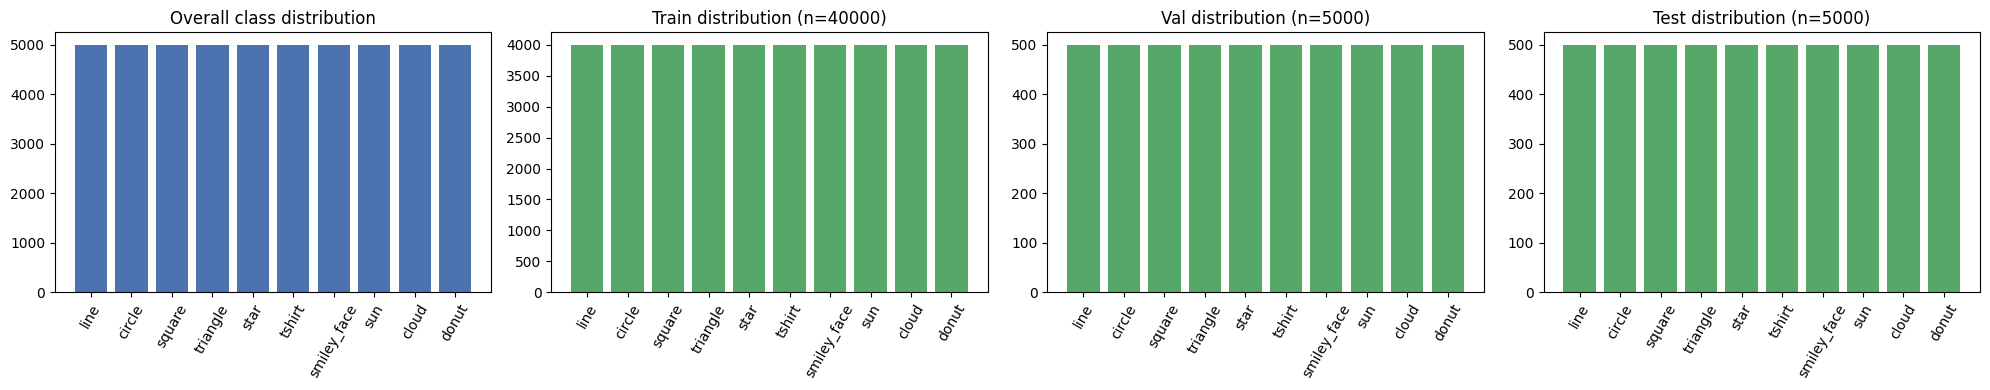

In [10]:
def plot_class_distribution(y, indices_by_split: Dict[str, np.ndarray], class_names: List[str]):
    fig, axes = plt.subplots(1, len(indices_by_split) + 1, figsize=(5 * (len(indices_by_split) + 1), 4))

    # Overall distribution
    counts_all = np.bincount(y, minlength=len(class_names))
    axes[0].bar(class_names, counts_all, color="#4C72B0")
    axes[0].set_title("Overall class distribution")
    axes[0].tick_params(axis='x', rotation=60)

    for ax, (split_name, idx) in zip(axes[1:], indices_by_split.items()):
        counts = np.bincount(y[idx], minlength=len(class_names))
        ax.bar(class_names, counts, color="#55A868")
        ax.set_title(f"{split_name} distribution (n={len(idx)})")
        ax.tick_params(axis='x', rotation=60)

    plt.tight_layout()
    plt.show()


plot_class_distribution(y_all, {"Train": train_idx, "Val": val_idx, "Test": test_idx}, CLASS_NAMES)

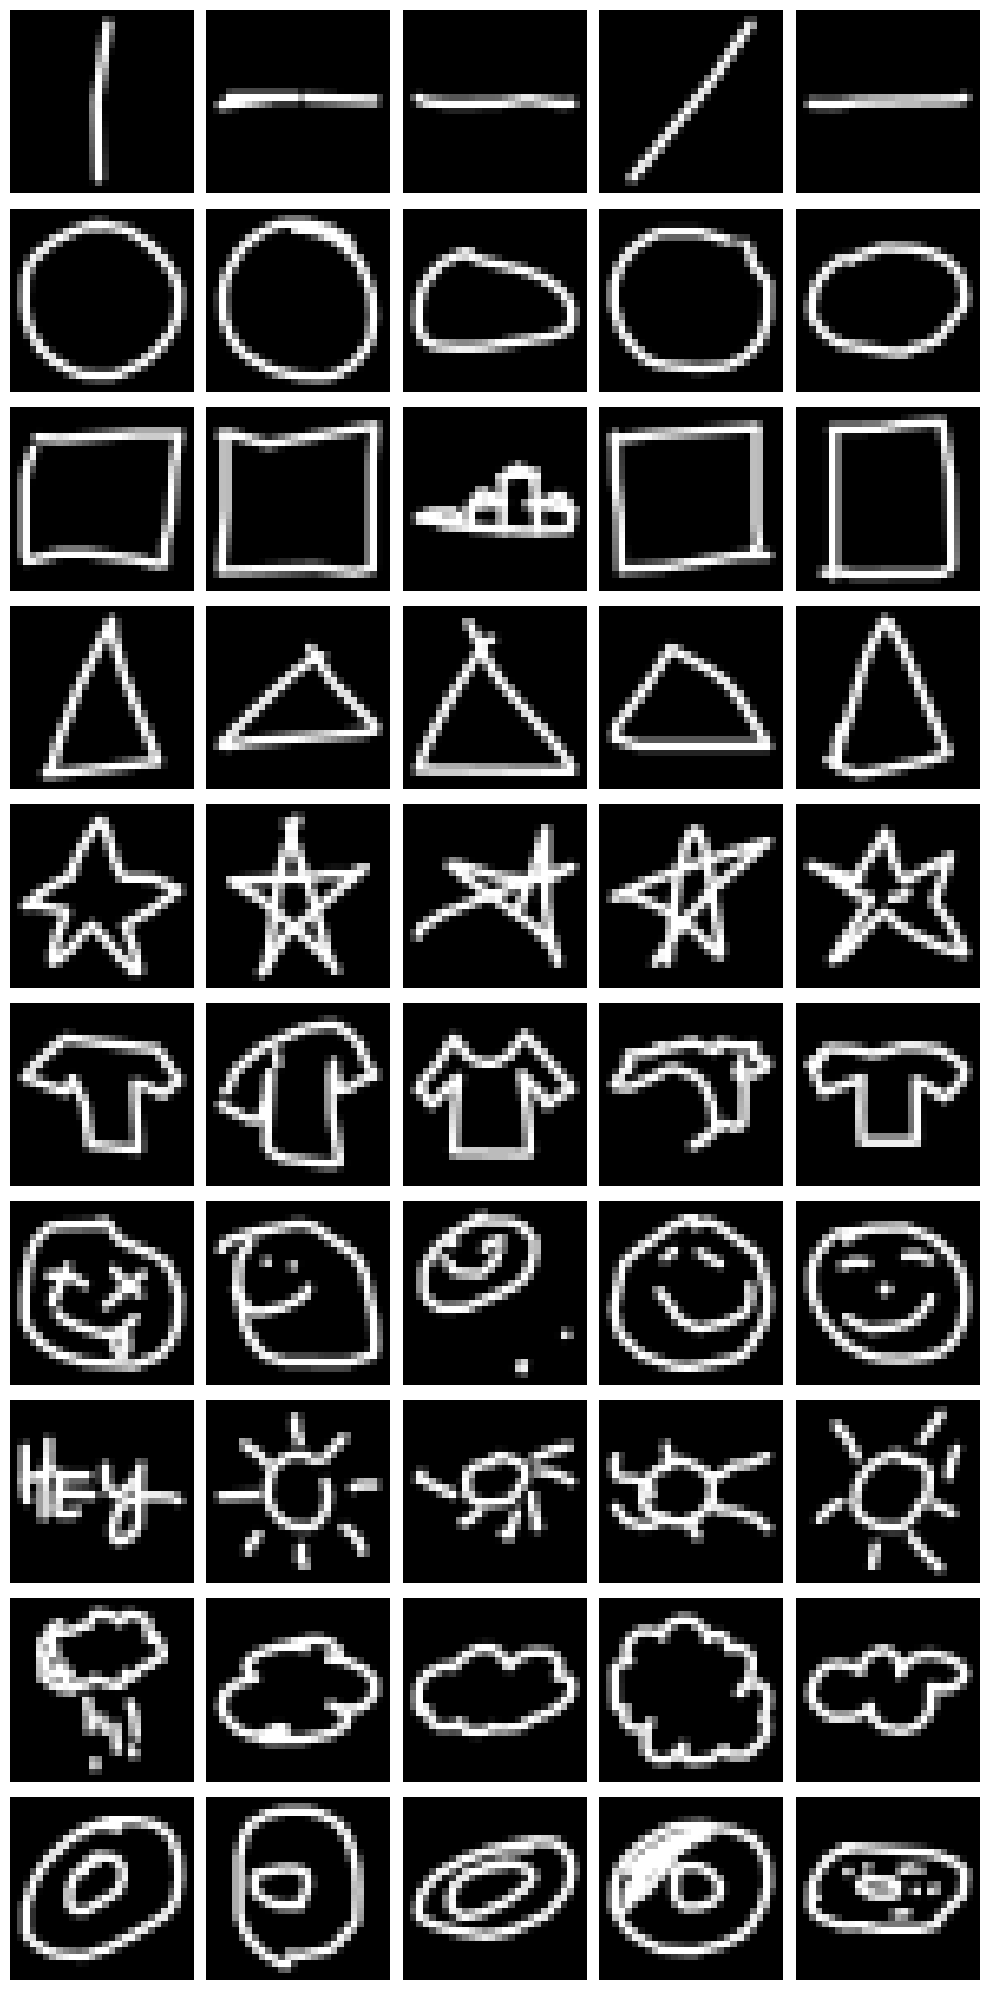

In [11]:
# Sample a few doodles per class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(10, 2 * NUM_CLASSES))
rng = np.random.default_rng(SEED)
for row, cls in enumerate(range(NUM_CLASSES)):
    cls_idx = np.where(y_all == cls)[0]
    sample_idx = rng.choice(cls_idx, size=5, replace=False)
    for col, si in enumerate(sample_idx):
        ax = axes[row, col]
        ax.imshow(X_all[si].reshape(28, 28), cmap="gray")
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(CLASS_NAMES[row], rotation=0, labelpad=40, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Load the pretrained MobileNetV4 model

We use:

`mobilenetv4_conv_small_050.e3000_r224_in1k`

The model is pretrained on **ImageNet-1k** and is loaded through `timm`.

### Why this model?

The later experiments will move from centralized fine-tuning to federated training. Model size therefore matters from the beginning.

MobileNetV4 Conv Small 0.5 is a useful compromise:

- **Pretrained representation:** ImageNet-1k weights provide a strong visual initialization instead of learning all visual features from scratch.
- **Small model:** the upstream model has about 2.2 million parameters.
- **Low compute:** the published configuration is approximately 0.1 GMACs.
- **FL suitability:** fewer parameters reduce local client compute, memory requirements, and the amount of model state that must be communicated during FL rounds.
- **Standard input pipeline:** the model is supported directly by `timm`, including its pretrained preprocessing configuration.

The original ImageNet classifier predicts 1,000 classes. For QuickDraw, `timm.create_model(..., num_classes=10)` replaces that classifier with a new 10-class head while retaining the pretrained backbone weights.

All model parameters remain trainable in this notebook. This is full fine-tuning rather than feature extraction.

In [12]:
MODEL_NAME = "mobilenetv4_conv_small_050.e3000_r224_in1k"

base_model = timm.create_model(MODEL_NAME, pretrained=True)
data_config = timm.data.resolve_model_data_config(base_model)
print("Pretrained model data config:", data_config)

IMG_SIZE = data_config["input_size"][-1]
MEAN = data_config["mean"]
STD = data_config["std"]
print(f"Input size: {IMG_SIZE}x{IMG_SIZE}, mean={MEAN}, std={STD}")

Pretrained model data config: {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.875, 'crop_mode': 'center'}
Input size: 224x224, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)


In [13]:
# Transform pipeline built from the pretrained model's own data config
train_transform = timm.data.create_transform(**data_config, is_training=True)
eval_transform = timm.data.create_transform(**data_config, is_training=False)

print(train_transform)
print(eval_transform)

Compose(
    RandomResizedCropAndInterpolation(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bicubic)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.6, 1.4), saturation=(0.6, 1.4), hue=None)
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)
Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)


In [14]:
train_ds = QuickDrawArrayDataset(X_all, y_all, train_idx, train_transform)
val_ds = QuickDrawArrayDataset(X_all, y_all, val_idx, eval_transform)
test_ds = QuickDrawArrayDataset(X_all, y_all, test_idx, eval_transform)

BATCH_SIZE = 128

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 312 | Val batches: 40 | Test batches: 40


In [15]:
# Re-create the model with the classifier head sized for our 10 classes
# Backbone weights remain pretrained
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES)
model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {n_params:,} | Trainable params: {n_trainable:,}")

Total params: 970,762 | Trainable params: 970,762


## 9. Evaluation helper

The evaluation function measures cross-entropy loss and classification accuracy without updating model parameters. The same function is reused for validation and test evaluation so that all reported metrics are computed consistently.

In [16]:
@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device, criterion: nn.Module):
    model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += images.size(0)

    avg_loss = total_loss / total_count
    accuracy = 100.0 * total_correct / total_count
    return avg_loss, accuracy

## 10. Pre-fine-tuning baseline

Before fine-tuning, we evaluate the model with its pretrained backbone and newly initialized 10-class classifier.

This measurement is useful as a sanity check. The backbone contains ImageNet knowledge, but the new classifier has not yet learned how those features map to the 10 QuickDraw classes. Accuracy should therefore be low before task-specific training.

The purpose of this baseline is to make the effect of fine-tuning visible. It is not a comparison against training a complete MobileNetV4 from random initialization.

In [17]:
baseline_criterion = nn.CrossEntropyLoss()

print("Running baseline inference with the original pretrained model (untrained head)...\n")
baseline_metrics = {}
for split_name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    loss, acc = evaluate(model, loader, DEVICE, baseline_criterion)
    baseline_metrics[split_name] = {"loss": loss, "accuracy": acc}
    print(f"[Baseline | {split_name:5s}] loss: {loss:.4f} | acc: {acc:.2f}%")

Running baseline inference with the original pretrained model (untrained head)...

[Baseline | train] loss: 7.8110 | acc: 6.97%
[Baseline | val  ] loss: 8.5807 | acc: 5.64%
[Baseline | test ] loss: 8.5695 | acc: 6.00%


## 11. Fine-tuning

The complete model is fine-tuned with AdamW and cross-entropy loss. A cosine learning-rate schedule is used across a maximum of 15 epochs.

Checkpoint selection is based only on **validation accuracy**. Training stops when validation accuracy does not improve for the configured patience window, and the weights from the best validation epoch are restored.

The notebook also prints test metrics during training. These test values are not used for optimization, early stopping, or checkpoint selection. In a strict benchmark workflow, the test set should normally be evaluated only once after all model-selection decisions have been completed.

In [18]:
NUM_EPOCHS = 15
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 4  # early stopping patience (epochs without val-acc improvement)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)


def train_one_epoch(model, loader, device, criterion, optimizer):
    model.train()
    total_loss, total_correct, total_count = 0.0, 0, 0

    for images, labels in tqdm(loader, desc="train", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += images.size(0)

    avg_loss = total_loss / total_count
    accuracy = 100.0 * total_correct / total_count
    return avg_loss, accuracy

In [19]:
history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [],
    "test_loss": [], "test_acc": [],
}

best_val_acc = -1.0
best_epoch = -1
epochs_without_improvement = 0
best_state_dict = None

print(f"Starting fine-tuning for up to {NUM_EPOCHS} epochs (early stopping patience={PATIENCE})...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, DEVICE, criterion, optimizer)
    val_loss, val_acc = evaluate(model, val_loader, DEVICE, criterion)
    test_loss, test_acc = evaluate(model, test_loader, DEVICE, criterion)

    scheduler.step()
    elapsed = time.time() - t0

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    history["test_loss"].append(test_loss); history["test_acc"].append(test_acc)

    print(
        f"[Epoch {epoch:02d}/{NUM_EPOCHS}] "
        f"train_loss: {train_loss:.4f} train_acc: {train_acc:.2f}% | "
        f"val_loss: {val_loss:.4f} val_acc: {val_acc:.2f}% | "
        f"test_loss: {test_loss:.4f} test_acc: {test_acc:.2f}% | "
        f"({elapsed:.1f}s)"
    )

    # Early stopping on validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        epochs_without_improvement = 0
        best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"  -> New best val_acc: {best_val_acc:.2f}% (epoch {best_epoch}). Saving checkpoint in memory.")
    else:
        epochs_without_improvement += 1
        print(f"  -> No improvement for {epochs_without_improvement}/{PATIENCE} epoch(s).")
        if epochs_without_improvement >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch} (best val_acc={best_val_acc:.2f}% at epoch {best_epoch}).")
            break

# Restore best weights found during training
if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
    print(f"\nRestored model weights from best epoch ({best_epoch}, val_acc={best_val_acc:.2f}%).")

Starting fine-tuning for up to 15 epochs (early stopping patience=4)...



train:   0%|          | 0/312 [00:00<?, ?it/s]

[Epoch 01/15] train_loss: 0.8596 train_acc: 78.16% | val_loss: 0.1774 val_acc: 95.80% | test_loss: 0.1748 test_acc: 95.54% | (219.1s)
  -> New best val_acc: 95.80% (epoch 1). Saving checkpoint in memory.


train:   0%|          | 0/312 [00:00<?, ?it/s]

[Epoch 02/15] train_loss: 0.4386 train_acc: 86.07% | val_loss: 0.1530 val_acc: 96.32% | test_loss: 0.1569 test_acc: 95.74% | (222.3s)
  -> New best val_acc: 96.32% (epoch 2). Saving checkpoint in memory.


...

[Epoch 13/15] train_loss: 0.2553 train_acc: 91.62% | val_loss: 0.0972 val_acc: 97.38% | test_loss: 0.0995 test_acc: 97.46% | (230.9s)
  -> New best val_acc: 97.38% (epoch 13). Saving checkpoint in memory.


train:   0%|          | 0/312 [00:00<?, ?it/s]

[Epoch 14/15] train_loss: 0.2510 train_acc: 91.70% | val_loss: 0.0974 val_acc: 97.34% | test_loss: 0.1000 test_acc: 97.42% | (228.3s)
  -> No improvement for 1/4 epoch(s).


train:   0%|          | 0/312 [00:00<?, ?it/s]

[Epoch 15/15] train_loss: 0.2492 train_acc: 91.83% | val_loss: 0.0961 val_acc: 97.48% | test_loss: 0.0969 test_acc: 97.50% | (228.6s)
  -> New best val_acc: 97.48% (epoch 15). Saving checkpoint in memory.

Restored model weights from best epoch (15, val_acc=97.48%).


## 12. Training curves

The loss and accuracy curves are used to inspect optimization behavior and the gap between training and validation performance.

The vertical marker identifies the epoch selected by validation accuracy. Since the best checkpoint is restored after early stopping, the final model corresponds to that validation-selected epoch rather than necessarily to the last executed epoch.

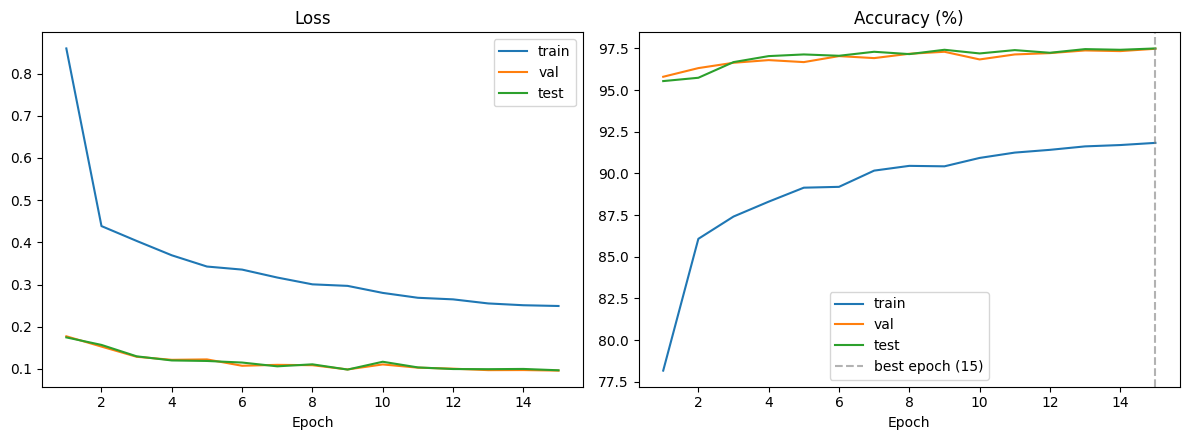

In [20]:
epochs_ran = len(history["train_loss"])
xs = range(1, epochs_ran + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(xs, history["train_loss"], label="train")
axes[0].plot(xs, history["val_loss"], label="val")
axes[0].plot(xs, history["test_loss"], label="test")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(xs, history["train_acc"], label="train")
axes[1].plot(xs, history["val_acc"], label="val")
axes[1].plot(xs, history["test_acc"], label="test")
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"best epoch ({best_epoch})")
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Final evaluation

The selected checkpoint is evaluated on the training, validation, and test subsets and compared with the pre-fine-tuning baseline.

The key result for the next stage is the validation and test performance of the selected checkpoint. A strong result confirms that the public-data fine-tuning stage has produced a useful initialization before federated client training begins.

Exact metrics should be taken from a fresh execution of this notebook and not copied from a previous run.

In [21]:
print("Final evaluation using best (early-stopped) checkpoint:\n")
final_metrics = {}
for split_name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    loss, acc = evaluate(model, loader, DEVICE, criterion)
    final_metrics[split_name] = {"loss": loss, "accuracy": acc}
    base = baseline_metrics[split_name]
    print(
        f"[{split_name:5s}] baseline_acc: {base['accuracy']:.2f}% -> finetuned_acc: {acc:.2f}% "
        f"(delta: {acc - base['accuracy']:+.2f}pp) | "
        f"baseline_loss: {base['loss']:.4f} -> finetuned_loss: {loss:.4f}"
    )

Final evaluation using best (early-stopped) checkpoint:

[train] baseline_acc: 6.97% -> finetuned_acc: 92.29% (delta: +85.32pp) | baseline_loss: 7.8110 -> finetuned_loss: 0.2378
[val  ] baseline_acc: 5.64% -> finetuned_acc: 97.48% (delta: +91.84pp) | baseline_loss: 8.5807 -> finetuned_loss: 0.0961
[test ] baseline_acc: 6.00% -> finetuned_acc: 97.50% (delta: +91.50pp) | baseline_loss: 8.5695 -> finetuned_loss: 0.0969


## 14. Save the model for the FL stage

The selected model weights are saved in `.safetensors` format together with a JSON configuration file.

The configuration records the model identifier, class ordering, input preprocessing parameters, selected epoch, and evaluation metrics. Keeping these values next to the checkpoint makes the model artifact easier to reproduce and prevents label-order or preprocessing mismatches when it is loaded by later FL notebooks.

The saved checkpoint is the main output of this centralized preparation stage.

In [22]:
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# safetensors requires contiguous, non-shared tensors
state_dict = model.state_dict()
state_dict = {k: v.contiguous().cpu() for k, v in state_dict.items()}

safetensors_path = OUTPUT_DIR / "mobilenetv4_small_quickdraw10.safetensors"
save_safetensors(state_dict, str(safetensors_path))
print(f"Saved fine-tuned weights to: {safetensors_path}")

config = {
    "model_name": MODEL_NAME,
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "quickdraw_file_names": QUICKDRAW_FILE_NAMES,
    "input_size": data_config["input_size"],
    "mean": list(MEAN),
    "std": list(STD),
    "best_epoch": best_epoch,
    "best_val_accuracy": best_val_acc,
    "final_metrics": final_metrics,
    "baseline_metrics": baseline_metrics,
}
config_path = OUTPUT_DIR / "config.json"
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)
print(f"Saved config/metadata to: {config_path}")

Saved fine-tuned weights to: outputs/mobilenetv4_small_quickdraw10.safetensors
Saved config/metadata to: outputs/config.json


In [23]:
# Sanity check: reload the safetensors weights into a fresh model and confirm it matches.
from safetensors.torch import load_file as load_safetensors

reloaded_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES)
reloaded_state_dict = load_safetensors(str(safetensors_path))
missing, unexpected = reloaded_model.load_state_dict(reloaded_state_dict, strict=True)
print(f"Missing keys: {missing} | Unexpected keys: {unexpected}")

reloaded_model.to(DEVICE)
reload_loss, reload_acc = evaluate(reloaded_model, test_loader, DEVICE, criterion)
print(f"Reloaded model test accuracy: {reload_acc:.2f}% (loss: {reload_loss:.4f}) - should match the finetuned test metrics above.")

Missing keys: [] | Unexpected keys: []
Reloaded model test accuracy: 97.50% (loss: 0.0969) - should match the finetuned test metrics above.


## 15. Handoff to federated learning

At this point we have a reproducible task definition, a lightweight pretrained architecture, a public-data fine-tuning procedure, and a saved task-specific checkpoint.

The next FL notebooks can use this checkpoint as the common initial global model. From there, the experimental focus can move to the distributed setting.

This design keeps the experiment realistic. The federated stage starts from a model that already contains general visual knowledge and has been adapted to the target task using public data, rather than asking distributed clients to learn the complete visual representation from random initialization.